<div align="center" style="padding:40px 24px;background:linear-gradient(135deg,#0e1a2e 0%,#13223b 100%);border-radius:14px;border-bottom:5px solid #ffd43b;">
  <p style="margin:0;color:#6aaef0;font-family:monospace;font-weight:700;font-size:14px;letter-spacing:.16em;text-transform:uppercase;">The AI Learning Hub · Lição 02 · Machine Learning: fundamentos</p>
  <h1 style="margin:14px 0 6px;color:#f1f5fb;font-size:42px;">03 · Aprendizagem não supervisionada</h1>
  <p style="margin:0;color:#b4c2d8;font-size:18px;">Que estrutura existe sem labels?</p>
</div>

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/the-ai-learning-hub/02-machine-learning-fundamentals/blob/main/02_unsupervised_learning/notebooks/03_Unsupervised_Learning.ipynb) [![Slides](https://img.shields.io/badge/slides-Lição_02-ffd43b)](https://the-ai-learning-hub.github.io/02-machine-learning-fundamentals/#nao-supervisionada)

## 🎯 Objetivos de aprendizagem

No fim deste notebook és capaz de:

- implementar o K-Means à mão (atribuir → atualizar) e compará-lo com o `KMeans` do scikit-learn;
- escolher *k* com o método do cotovelo e com o *silhouette*, e saber porque nenhum dos dois é infalível;
- explicar porque é obrigatório pôr as *features* na mesma escala antes de medir distâncias;
- usar o DBSCAN quando os grupos não são "bolas" e interpretar `eps`, `min_samples` e o ruído;
- usar a PCA para reduzir dimensão, visualizar 64 dimensões em 2D e reconstruir imagens;
- avaliar *clusters* sem labels (e com labels escondidas) e discutir os limites da segmentação.

**⏱️ Duração estimada:** ≈ 25 min · **📋 Pré-requisitos:** notebooks 01 e 02 (pipelines, escala) e NumPy básico · **▶️ Como usar:** executa cada célula com `Shift`+`Enter`, por ordem.

## 📑 Índice

1. [🧭 Business Understanding (compreensão do negócio)](#sec-1)
2. [🔍 Data Understanding (compreensão dos dados)](#sec-2)
3. [🧹 Data Preparation (preparação dos dados): a escala decide tudo](#sec-3)
4. [🤖 Modeling (modelação) A — K-Means passo a passo](#sec-4)
5. [🤖 Modeling B — escolher o número de grupos](#sec-5)
6. [🤖 Modeling C — DBSCAN: grupos com forma livre](#sec-6)
7. [🤖 Modeling D — PCA: comprimir sem perder o essencial](#sec-7)
8. [📏 Evaluation (avaliação): como avaliar sem labels?](#sec-8)
9. [🚀 Deployment (implementação) e limites](#sec-9)
10. [✏️ Exercícios](#sec-10)
11. [📌 Resumo](#sec-11)
12. [📚 Para saber mais](#sec-12)

<a id="sec-0"></a>

## ⚙️ Preparar o ambiente

In [1]:
# ⚙️ Preparar o ambiente: funciona localmente (VS Code/Jupyter) e no Google Colab
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path("/content/02-machine-learning-fundamentals")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/the-ai-learning-hub/02-machine-learning-fundamentals.git",
                        str(ROOT)], check=True)
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())

try:  # o Colab já traz tudo; localmente usa `uv sync` (ver README)
    import sklearn, seaborn  # noqa: F401
except ImportError:  # plano B: instala as dependências declaradas no pyproject.toml
    import tomllib
    deps = tomllib.loads((ROOT / "pyproject.toml").read_text(encoding="utf-8"))["project"]["dependencies"]
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *deps], check=True)

sys.path.insert(0, str(ROOT))
print("Raiz do projeto:", ROOT.name, "(Colab)" if IN_COLAB else "(local)")

Raiz do projeto: 02-machine-learning-fundamentals (local)


> 💡 **Dica:** no Colab não tens de instalar nada. Localmente, corre `uv sync` na raiz do projeto e escolhe o kernel `.venv` no Jupyter/VS Code.
>
> 📖 **Primeira vez?** Se algum termo (dataset, *feature*, alvo, modelo, treinar, prever, erro, *overfitting*) for novo, lê o [Vocabulário do notebook 01](../../01_supervised_learning/notebooks/01_CRISP-DM_House_Prices.ipynb#vocab). Cada notebook volta a explicar os termos novos na primeira vez que aparecem.

<a id="sec-1"></a>

# 1. 🧭 Business Understanding (compreensão do negócio)

Na aprendizagem **supervisionada** (notebooks 01 e 02) tínhamos uma coluna-alvo: o preço, a sobrevivência. Aqui **não há alvo**. Há apenas pontos e uma pergunta: *existe estrutura nestes dados que um humano não vê à primeira?*

Três pedidos típicos de "negócio" que se resolvem sem labels:

| Pedido | Técnica | Neste notebook |
|---|---|---|
| "Quero agrupar clientes/casas parecidas para campanhas ou preços de referência" | *clustering* (K-Means, DBSCAN) | secções 4 a 6 |
| "Tenho 64 (ou 6000) colunas; quero ver e comprimir" | redução de dimensão (PCA) | secção 7 |
| "Quero detetar o que não encaixa em nenhum grupo" | ruído/*outliers* (DBSCAN) | secção 6 |

**Sucesso aqui não é uma métrica única.** Um agrupamento é bom se for *estável*, *interpretável* e *acionável* (alguém consegue fazer algo diferente por grupo). Vamos medir o que se pode medir, mas sem esquecer isto.

### 📖 Palavras que vão aparecer (mini-glossário)

Se alguma te parecer nova, o **📖 Vocabulário** do [notebook 01](../../01_supervised_learning/notebooks/01_CRISP-DM_House_Prices.ipynb#vocab) explica o básico (dataset, *feature*, alvo, modelo, treinar). Aqui ficam as específicas deste notebook; cada uma é explicada de novo quando aparece:

| Termo | Em palavras simples |
|---|---|
| ***label*** (rótulo) | a "resposta certa" de cada exemplo (por exemplo, o dígito escrito na imagem). **Aqui não a damos ao algoritmo.** |
| **aprendizagem não supervisionada** | o algoritmo só recebe os dados e procura estrutura sozinho |
| ***cluster*** (grupo) | conjunto de exemplos parecidos entre si e diferentes dos outros |
| **centroide** | o "centro" de um grupo: a média das posições dos seus pontos |
| **distância** | quão longe estão dois exemplos (aqui, a distância "em linha reta", euclidiana) |
| ***outlier*** / ruído | exemplo isolado que não pertence a nenhum grupo |
| **dimensão** | cada coluna de um exemplo (as imagens têm 64 dimensões: 64 pixéis) |

### 💬 Discussão — O que é um "bom" agrupamento?

Uma imobiliária pede-te para "segmentar as casas". Que perguntas farias antes de abrir o Python? Como saberias, daqui a um mês, que a segmentação foi útil?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Sem alvo não há "accuracy". O critério tem de vir do uso: para que decisão serve cada segmento (preço de referência, tipo de anúncio, comercial a contactar)? Perguntas úteis: quantos grupos consegue a equipa gerir? Que variáveis podem (e não podem) entrar? Como se vai usar um grupo novo? Ao longo do notebook vais ver que o mesmo conjunto de dados dá resultados muito diferentes consoante escala, *k* e algoritmo, por isso o critério de utilidade (interpretável, estável, acionável) pesa mais do que qualquer número.
</details>

<a id="sec-2"></a>

# 2. 🔍 Data Understanding (compreensão dos dados)

## 🗂️ Conhecer os dados

Antes de qualquer algoritmo, perguntamos: **o que são estes dados?** Usamos quatro conjuntos. Três são pequenos e **inventados de propósito**: assim *sabemos a resposta certa* e podemos ver se o algoritmo a descobre. O quarto é real.

| Conjunto | O que é | De onde vem | Uma linha = … | Tamanho |
|---|---|---|---|---|
| **blobs** (`make_blobs`) | pontos em 2D, agrupados em "bolas" | **gerado** pelo scikit-learn, com uma *seed* fixa | um ponto $(x_1, x_2)$ | 300 × 2 |
| **moons** (`make_moons`) | pontos em 2D, em forma de duas "luas" | **gerado** pelo scikit-learn | um ponto $(x_1, x_2)$ | 300 × 2 |
| **dígitos** (`load_digits`) | imagens de números escritos à mão | dados reais incluídos no scikit-learn (UCI, optical recognition of handwritten digits) | uma imagem 8×8 de um dígito (0–9) | 1797 × 64 |
| **casas de Windsor** | características e preço de casas vendidas | arquivo oficial do *Journal of Applied Econometrics* (Anglin & Gençay, 1996); descarregado no 1.º uso para `data/` | uma casa vendida | 546 × 12 |

**Porque inventar dados?** Num problema real não sabemos se o algoritmo acertou, porque não há "resposta certa" para comparar. Com dados sintéticos *nós* escolhemos os grupos verdadeiros e podemos medir o erro. É o mesmo que treinar com um mapa antes de ir a um sítio desconhecido.

**Seeds:** `random_state=42` em tudo o que é gerado ou ajustado (*seed* = número que fixa o "acaso" para o resultado ser repetível).

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.datasets import make_blobs, make_moons, load_digits
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler

from src.plotting import apply_style, PALETTE, CYCLE, MARKERS, save_fig
from src.data import load_housing, HOUSING_NUMERIC

apply_style()
SEED = 42
FIG = ROOT / "assets" / "figures"

# 🖌️ Auxiliar de gráficos: números à portuguesa (vírgula decimal, espaço nos milhares) e letra ≥ 10 pt
import re
import matplotlib as mpl
from matplotlib.ticker import FuncFormatter
from src.plotting import fmt_pt


def _decimals(axis):
    """Casas decimais necessárias para os valores dos ticks (0 a 3; em escala log, as que o menor tick pede)."""
    locs = np.asarray(axis.get_majorticklocs(), dtype=float)
    if axis.get_scale() == "log":
        locs = np.abs(locs[locs != 0])
        return int(min(4, max(0, np.ceil(-np.log10(locs.min()))))) if locs.size else 0
    for d in range(4):
        if np.allclose(locs, np.round(locs, d), atol=1e-9):
            return d
    return 3


def finish(fig, path=None):
    """Formata os números à portuguesa, garante letra >= 10 pt e (opcionalmente) guarda a figura."""
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            if type(axis.get_major_formatter()).__name__ in ("StrCategoryFormatter", "FixedFormatter", "NullFormatter"):
                continue
            axis.set_major_formatter(FuncFormatter(lambda v, _, a=axis: fmt_pt(v, _decimals(a))))
    for text in fig.findobj(mpl.text.Text):
        s = text.get_text()
        if re.search(r"\d\.\d", s):
            text.set_text(re.sub(r"(\d)\.(\d)", r"\1,\2", s))
        if text.get_fontsize() < 10:
            text.set_fontsize(10)
    if path is not None:
        save_fig(fig, path)


_show = plt.show


def _show_pt(*args, **kwargs):
    for num in plt.get_fignums():
        finish(plt.figure(num))
    return _show(*args, **kwargs)


plt.show = _show_pt


X_blobs, y_blobs = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=SEED)
X_moons, y_moons = make_moons(n_samples=300, noise=0.07, random_state=SEED)
digits = load_digits()
print("blobs :", X_blobs.shape, "| moons:", X_moons.shape, "| digits:", digits.data.shape)

blobs : (300, 2) | moons: (300, 2) | digits: (1797, 64)


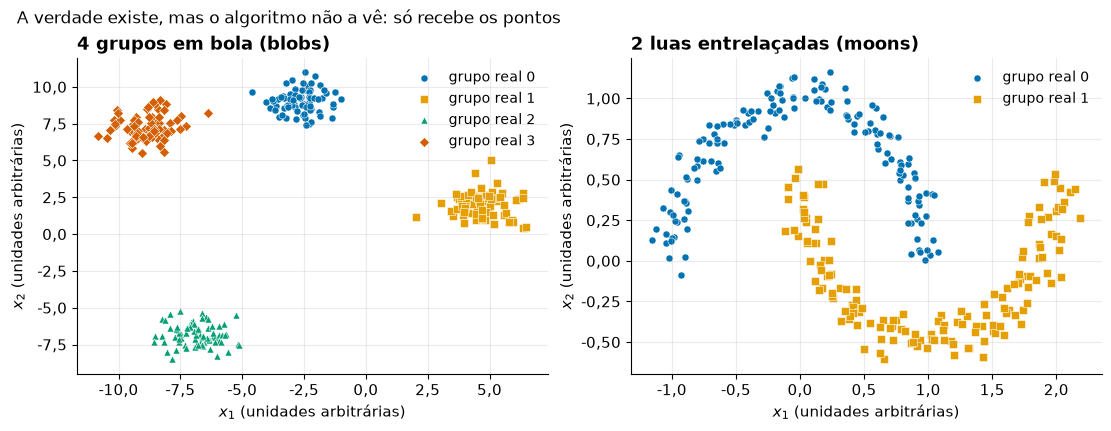

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
for ax, X, y, title in ((axes[0], X_blobs, y_blobs, "4 grupos em bola (blobs)"),
                        (axes[1], X_moons, y_moons, "2 luas entrelaçadas (moons)")):
    for k in np.unique(y):
        ax.scatter(X[y == k, 0], X[y == k, 1], s=26, marker=MARKERS[k], color=CYCLE[k], edgecolor="white",
                   linewidth=0.4, label=f"grupo real {k}")
    ax.set(title=title, xlabel="$x_1$ (unidades arbitrárias)", ylabel="$x_2$ (unidades arbitrárias)")
    ax.legend(fontsize=10)
fig.suptitle("A verdade existe, mas o algoritmo não a vê: só recebe os pontos", x=0.01, ha="left", fontsize=12)

finish(fig, FIG / "03_data_overview.png"); plt.show()

### Os dígitos: uma imagem é uma linha de 64 números

Cada imagem tem 8×8 = 64 pixéis; cada pixel é um número de 0 (branco) a 16 (preto). Para o algoritmo, uma imagem é só uma lista de 64 números, ou seja, **um ponto num espaço com 64 dimensões**. As *labels* (0 a 9) existem, mas **escondemo-las** do algoritmo e só as usamos no fim para verificar.

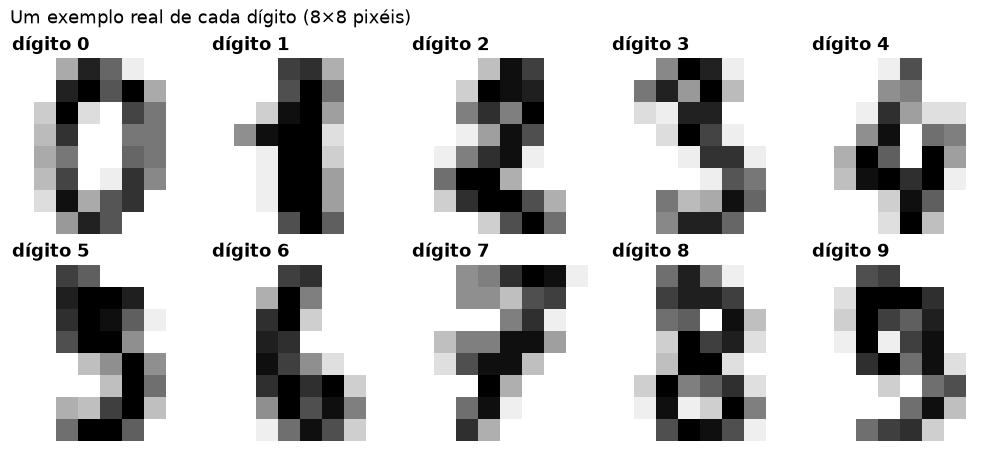

A primeira imagem como números (0 = branco, 16 = preto):
[[ 0  0  5 13  9  1  0  0]
 [ 0  0 13 15 10 15  5  0]
 [ 0  3 15  2  0 11  8  0]
 [ 0  4 12  0  0  8  8  0]
 [ 0  5  8  0  0  9  8  0]
 [ 0  4 11  0  1 12  7  0]
 [ 0  2 14  5 10 12  0  0]
 [ 0  0  6 13 10  0  0  0]]
labels do início: [0 1 2 3 4 5 6 7 8 9] | imagens: (1797, 8, 8) -> como linhas de 64 números: (1797, 64)


In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.4), layout="constrained")
for d, ax in enumerate(axes.ravel()):
    i = np.flatnonzero(digits.target == d)[0]
    ax.imshow(digits.images[i], cmap="gray_r"); ax.set_title(f"dígito {d}"); ax.axis("off")
fig.suptitle("Um exemplo real de cada dígito (8×8 pixéis)", x=0.01, ha="left")
finish(fig, FIG / "03_digits_samples.png"); plt.show()
print("A primeira imagem como números (0 = branco, 16 = preto):")
print(digits.images[0].astype(int))
print("labels do início:", digits.target[:10], "| imagens:", digits.images.shape, "-> como linhas de 64 números:", digits.data.shape)

### As casas de Windsor (o caso real)

**Ficha do dataset.** *O que é:* 546 casas vendidas em **Windsor (Ontário, Canadá)** entre julho e setembro de **1987**. *Fonte oficial:* arquivo do *Journal of Applied Econometrics* (Anglin & Gençay, 1996), descarregado no 1.º uso para `data/`. *Uma linha:* uma casa. *Preço:* dólares canadianos de 1987 (**CAD**). *Área do lote:* pés² (1 pé² ≈ 0,093 m²).

Neste notebook **não** há alvo: vamos agrupar as casas só pelas características físicas (5 colunas) e usar o preço **depois**, para perceber os grupos.

In [5]:
housing = load_housing()
meaning = {
    "price": ("preço de venda", "numérica", "CAD (1987)"), "lotsize": ("área do lote", "numérica", "pés²"),
    "bedrooms": ("quartos", "contagem", "n.º"), "bathrooms": ("casas de banho", "contagem", "n.º"),
    "stories": ("pisos", "contagem", "n.º"), "driveway": ("tem entrada para carros", "sim/não", "—"),
    "recreation": ("tem sala de jogos", "sim/não", "—"), "fullbase": ("tem cave completa", "sim/não", "—"),
    "gasheat": ("aquecimento a gás", "sim/não", "—"), "aircon": ("tem ar condicionado", "sim/não", "—"),
    "garage": ("lugares de garagem", "contagem", "n.º"), "prefer": ("bairro preferido", "sim/não", "—"),
}
columns_table = pd.DataFrame(
    [(c, *meaning[c], housing[c].iloc[0], "sim" if c in HOUSING_NUMERIC else "não (só interpretação)" if c == "price" else "não")
     for c in housing.columns],
    columns=["coluna", "significado", "tipo", "unidade", "exemplo (1.ª casa)", "usada no agrupamento?"]).set_index("coluna")
columns_table

,significado,tipo,unidade,exemplo (1.ª casa),usada no agrupamento?
coluna,,,,,
price,preço de venda,numérica,CAD (1987),42000,não (só interpretação)
lotsize,área do lote,numérica,pés²,5850,sim
bedrooms,quartos,contagem,n.º,3,sim
bathrooms,casas de banho,contagem,n.º,1,sim
stories,pisos,contagem,n.º,2,sim
driveway,tem entrada para carros,sim/não,—,yes,não
recreation,tem sala de jogos,sim/não,—,no,não
fullbase,tem cave completa,sim/não,—,yes,não
gasheat,aquecimento a gás,sim/não,—,no,não


In [6]:
housing.head()

,price,lotsize,bedrooms,bathrooms,stories,driveway,recreation,fullbase,gasheat,aircon,garage,prefer
0,42000,5850,3,1,2,yes,no,yes,no,no,1,no
1,38500,4000,2,1,1,yes,no,no,no,no,0,no
2,49500,3060,3,1,1,yes,no,no,no,no,0,no
3,60500,6650,3,1,2,yes,yes,no,no,no,0,no
4,61000,6360,2,1,1,yes,no,no,no,no,0,no


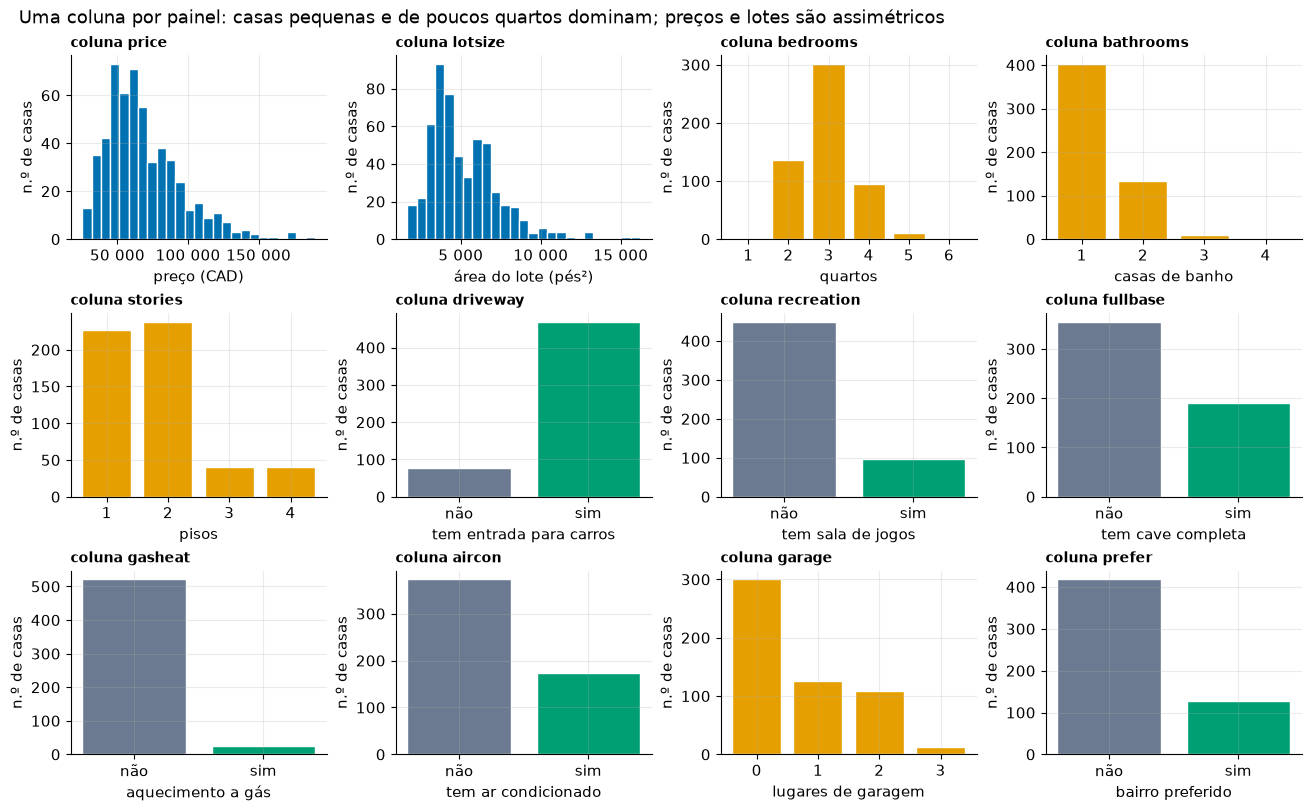

In [7]:
fig, axes = plt.subplots(3, 4, figsize=(13, 8), layout="constrained")
titles = {"price": "preço (CAD)", "lotsize": "área do lote (pés²)", "bedrooms": "quartos", "bathrooms": "casas de banho",
          "stories": "pisos", "garage": "lugares de garagem"}
for ax, col in zip(axes.ravel(), housing.columns):
    if col in titles and col in ("price", "lotsize"):
        ax.hist(housing[col], bins=25, color=PALETTE["blue"], edgecolor="white")
        ax.set(xlabel=titles[col], ylabel="n.º de casas")
    elif col in titles:
        counts = housing[col].value_counts().sort_index()
        ax.bar(counts.index.astype(str), counts.values, color=PALETTE["orange"], edgecolor="white")
        ax.set(xlabel=titles[col], ylabel="n.º de casas")
    else:
        counts = housing[col].value_counts().reindex(["no", "yes"])
        ax.bar(["não", "sim"], counts.values, color=[PALETTE["grey"], PALETTE["green"]], edgecolor="white")
        ax.set(xlabel=f"{meaning[col][0]}", ylabel="n.º de casas")
    ax.set_title(f"coluna {col}", fontsize=10)
fig.suptitle("Uma coluna por painel: casas pequenas e de poucos quartos dominam; preços e lotes são assimétricos", x=0.01, ha="left")
finish(fig, FIG / "03_housing_columns.png"); plt.show()

**Leitura:** quase todas as casas têm 2 a 4 quartos e 1 casa de banho; a maioria tem 1 ou 2 pisos. A área do lote e o preço têm uma "cauda" para a direita (poucas casas muito grandes e caras). Repara nas escalas: `lotsize` anda na casa dos milhares e `bedrooms` na casa das unidades; isto vai importar na secção 3.

### 💬 Discussão — O que é um grupo?

Olha para as duas figuras. Na da direita, dirias que há 2 grupos ou 1? E se um algoritmo só souber medir "distância ao centro do grupo"?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Um humano vê duas luas porque usa **continuidade** (pontos vizinhos encadeados). Um algoritmo baseado em centros (K-Means) só sabe "distância ao centro", o que pressupõe grupos compactos e redondos. Ou seja, a definição de "grupo" está *escondida na escolha do algoritmo*. Já vais ver (secção 6) o K-Means a cortar as luas ao meio, e o DBSCAN, que define grupo como "região densa e contínua", a acertar.
</details>

<a id="sec-3"></a>

# 3. 🧹 Data Preparation (preparação dos dados): a escala decide tudo

Algoritmos de *clustering* medem **distâncias** (quão longe estão dois exemplos). Se uma coluna está em pés² (milhares) e outra em número de quartos (unidades), a distância é praticamente só pés². Vamos ver isto nas casas de Windsor, com as 5 *features* numéricas (`lotsize`, `bedrooms`, `bathrooms`, `stories`, `garage`). O preço **não entra** no agrupamento; usamo-lo depois, para interpretar. **Escalar** (*standardize*) = converter cada coluna para média 0 e desvio-padrão 1 (o desvio-padrão mede o quanto os valores se afastam da média), para que todas tenham o mesmo peso nas distâncias.

In [8]:
X_house = housing[HOUSING_NUMERIC].to_numpy(dtype=float)
print(housing[HOUSING_NUMERIC].describe().loc[["mean", "std", "min", "max"]].round(1))

      lotsize  bedrooms  bathrooms  stories  garage
mean   5150.3       3.0        1.3      1.8     0.7
std    2168.2       0.7        0.5      0.9     0.9
min    1650.0       1.0        1.0      1.0     0.0
max   16200.0       6.0        4.0      4.0     3.0


In [9]:
km_raw = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X_house)                 # sem escalar
km_scaled = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(StandardScaler().fit_transform(X_house))
km_lot = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X_house[:, [0]])         # só lotsize

print("ARI(sem escala , só lotsize) =", round(adjusted_rand_score(km_raw.labels_, km_lot.labels_), 3))
print("ARI(com escala , só lotsize) =", round(adjusted_rand_score(km_scaled.labels_, km_lot.labels_), 3))

ARI(sem escala , só lotsize) = 1.0
ARI(com escala , só lotsize) = 0.24


O **ARI** (*Adjusted Rand Index*) compara duas partições: 1 = idênticas, ≈ 0 = tão parecidas como o acaso. Sem escala, o K-Means com 5 colunas dá **exatamente** a mesma partição que usar só `lotsize` (ARI = 1,0): as outras 4 colunas foram ignoradas. Com `StandardScaler` (média 0, desvio-padrão 1) passam todas a contar.

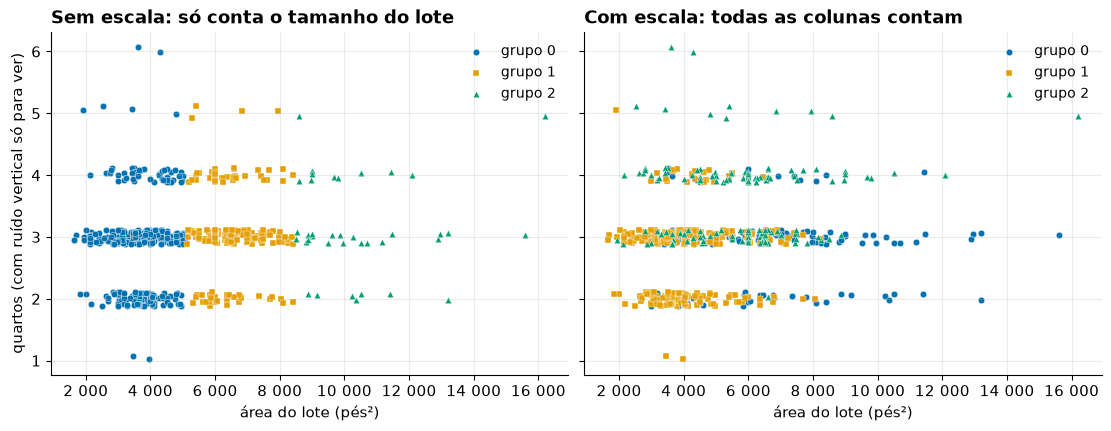

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True, layout="constrained")
jitter = np.random.default_rng(SEED).uniform(-0.12, 0.12, len(housing))
for ax, labels, title in ((axes[0], km_raw.labels_, "Sem escala: só conta o tamanho do lote"),
                          (axes[1], km_scaled.labels_, "Com escala: todas as colunas contam")):
    for k in range(3):
        m = labels == k
        ax.scatter(housing.loc[m, "lotsize"], housing.loc[m, "bedrooms"] + jitter[m], s=22, marker=MARKERS[k],
                   color=CYCLE[k], edgecolor="white", linewidth=0.3, label=f"grupo {k}")
    ax.set(title=title, xlabel="área do lote (pés²)")
    ax.legend(fontsize=10)
axes[0].set_ylabel("quartos (com ruído vertical só para ver)")
finish(fig, FIG / "03_scale_effect.png"); plt.show()

### 💬 Discussão — Escalar ou não escalar?

Os quartos são uma variável importante para quem compra. Sem escala, o K-Means ignorou-os por completo. É um "erro" do algoritmo ou da preparação dos dados? Haverá casos em que **não** quererias escalar?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

É um erro de **preparação**: o K-Means fez o que lhe pedimos (minimizar distâncias euclidianas), e a escala do `lotsize` é milhares de vezes maior. O ARI = 1,0 face ao agrupamento só por `lotsize` prova-o. Não escalar só faz sentido quando as unidades **já são comparáveis e a escala tem significado** (por exemplo, coordenadas geográficas em km). Escalar é também uma decisão de negócio: dar o mesmo peso a todas as colunas é uma escolha, e pode usar-se pesos explícitos.
</details>

### Segmentação de casas (curta, com interpretação)

Com as colunas escaladas e *k* = 3, o preço (que **não** foi usado) serve para dar nome aos segmentos. Valores em dólares canadianos de 1987 (CAD):

In [11]:
profile = (housing.assign(cluster=km_scaled.labels_)
           .groupby("cluster")
           .agg(casas=("price", "size"), preco_mediano_CAD=("price", "median"), lote_mediano_pes2=("lotsize", "median"),
                quartos=("bedrooms", "median"), casas_de_banho=("bathrooms", "median"),
                pisos=("stories", "median"), garagem=("garage", "median"))
           .sort_values("preco_mediano_CAD"))
profile.index = ["A", "B", "C"]
profile

,casas,preco_mediano_CAD,lote_mediano_pes2,quartos,casas_de_banho,pisos,garagem
A,285,52000.0,3930.0,3.0,1.0,2.0,0.0
B,121,70000.0,6600.0,3.0,1.0,1.0,2.0
C,140,87125.0,6000.0,4.0,2.0,2.0,1.0


**Leitura (por ordem de preço mediano):** **A**, o maior grupo, são casas de preço mais baixo (≈ 52 000 CAD), com lotes pequenos e sem garagem; **B** são casas de 1 piso com garagem dupla e preço intermédio (≈ 70 000 CAD); **C** são as maiores (4 quartos, 2 casas de banho) e as mais caras (≈ 87 000 CAD). O preço **nunca** entrou no agrupamento e ainda assim os grupos separam-no: sinal de que a estrutura é real. Mas cuidado, **os nomes A/B/C somos nós a inventá-los**: o algoritmo só devolveu números 0, 1, 2.

<a id="sec-4"></a>

# 4. 🤖 Modeling (modelação) A — K-Means passo a passo

## 🧠 Como funciona: K-Means

**Ideia simples.** Imagina que queres abrir 4 lojas para servir 300 casas espalhadas pelo mapa. Primeiro colocas as 4 lojas ao acaso; cada casa vai à mais próxima; depois mudas cada loja para o **centro** das casas que a escolheram; repetes. As lojas vão-se arrumando, e cada "zona de influência" é um *cluster*.

**Passos** (o algoritmo repete 1 e 2 até nada mudar):

1. **Atribuir:** cada ponto vai para o **centroide** (a "loja") mais próximo;
2. **Atualizar:** cada centroide passa a ser a **média** dos pontos que lhe foram atribuídos.

**Quando usar:** grupos compactos e mais ou menos redondos, com uma ideia de quantos são (*k*). **Cuidados:** é preciso escolher *k*; depende da escala; só vê bolas (secção 6); pode ficar preso numa solução má (vê-se abaixo). O que se minimiza é a **inércia** = soma dos quadrados das distâncias de cada ponto ao seu centroide (quanto menor, mais compactos os grupos).

O K-Means repete dois passos até nada mudar:

1. **Atribuir:** cada ponto vai para o centroide mais próximo;
2. **Atualizar:** cada centroide passa a ser a **média** dos pontos que lhe foram atribuídos.

Escrevemos isto em NumPy, com os 4 centroides iniciais escolhidos ao acaso entre os pontos (`seed=2`; mais abaixo vês o que acontece com `seed=0`), e mostramos as primeiras 3 iterações.

In [12]:
def assign(X, centroids):
    """Passo 1: índice do centroide mais próximo de cada ponto (distância euclidiana)."""
    dists = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)   # (n, k)
    return dists.argmin(axis=1)

def update(X, labels, centroids):
    """Passo 2: cada centroide passa a ser a média dos seus pontos (se ficar vazio, mantém-se)."""
    new = centroids.copy()
    for j in range(len(centroids)):
        if np.any(labels == j):
            new[j] = X[labels == j].mean(axis=0)
    return new

def inertia(X, labels, centroids):
    """Soma dos quadrados das distâncias de cada ponto ao seu centroide."""
    return float(((X - centroids[labels]) ** 2).sum())

def init_centroids(seed, k=4):
    """k pontos escolhidos ao acaso como centroides iniciais."""
    return X_blobs[np.random.default_rng(seed).choice(len(X_blobs), size=k, replace=False)].copy()

def run_kmeans(X, centroids, max_iter=30):
    """Repete atribuir/atualizar até os centroides pararem; devolve o histórico (centroides, labels, inércia)."""
    hist, cur = [], centroids.copy()
    for _ in range(max_iter):
        labels = assign(X, cur)
        hist.append((cur.copy(), labels, inertia(X, labels, cur)))
        new = update(X, labels, cur)
        if np.allclose(new, cur):
            break
        cur = new
    return hist

centroids = init_centroids(seed=2)
print("shapes: X", X_blobs.shape, "| centroides", centroids.shape)

shapes: X (300, 2) | centroides (4, 2)


In [13]:
history = run_kmeans(X_blobs, centroids)
print(f"convergiu em {len(history)} iterações: os centroides já não se mexem")
for i, (_, _, inert) in enumerate(history, 1):
    print(f"iteração {i}: inércia = {inert:8.1f}")

convergiu em 4 iterações: os centroides já não se mexem
iteração 1: inércia =   3278.6
iteração 2: inércia =    509.1
iteração 3: inércia =    362.8
iteração 4: inércia =    362.5


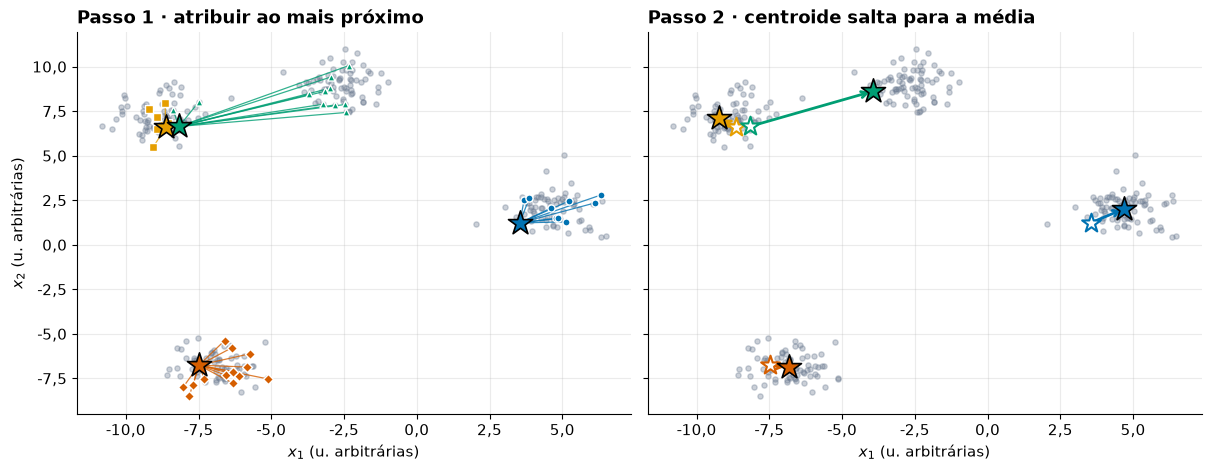

In [14]:
# O mecanismo, desenhado: (1) cada ponto liga ao centroide mais próximo; (2) cada centroide salta para a média dos seus pontos
cents0, labels0, _ = history[0]
cents1 = history[1][0]                                     # centroides depois do passo "atualizar"
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True, sharey=True, layout="constrained")
pick = np.random.default_rng(1).choice(len(X_blobs), 40, replace=False)
for ax in axes:
    ax.scatter(X_blobs[:, 0], X_blobs[:, 1], s=14, color=PALETTE["grey"], alpha=0.35)
for i in pick:
    j = labels0[i]
    axes[0].plot([X_blobs[i, 0], cents0[j, 0]], [X_blobs[i, 1], cents0[j, 1]], color=CYCLE[j], lw=0.9, alpha=0.8)
    axes[0].scatter(*X_blobs[i], s=26, marker=MARKERS[j], color=CYCLE[j], edgecolor="white", zorder=3)
for j in range(4):
    axes[0].scatter(*cents0[j], marker="*", s=330, color=CYCLE[j], edgecolor="black", linewidth=1.2, zorder=5)
    axes[1].scatter(*cents0[j], marker="*", s=200, color="white", edgecolor=CYCLE[j], linewidth=1.5, zorder=4)
    axes[1].scatter(*cents1[j], marker="*", s=330, color=CYCLE[j], edgecolor="black", linewidth=1.2, zorder=5)
    axes[1].annotate("", xy=cents1[j], xytext=cents0[j], arrowprops=dict(arrowstyle="->", color=CYCLE[j], lw=2))
axes[0].set(title="Passo 1 · atribuir ao mais próximo", xlabel="$x_1$ (u. arbitrárias)", ylabel="$x_2$ (u. arbitrárias)")
axes[1].set(title="Passo 2 · centroide salta para a média", xlabel="$x_1$ (u. arbitrárias)")
finish(fig, FIG / "03_kmeans_mechanism.png"); plt.show()

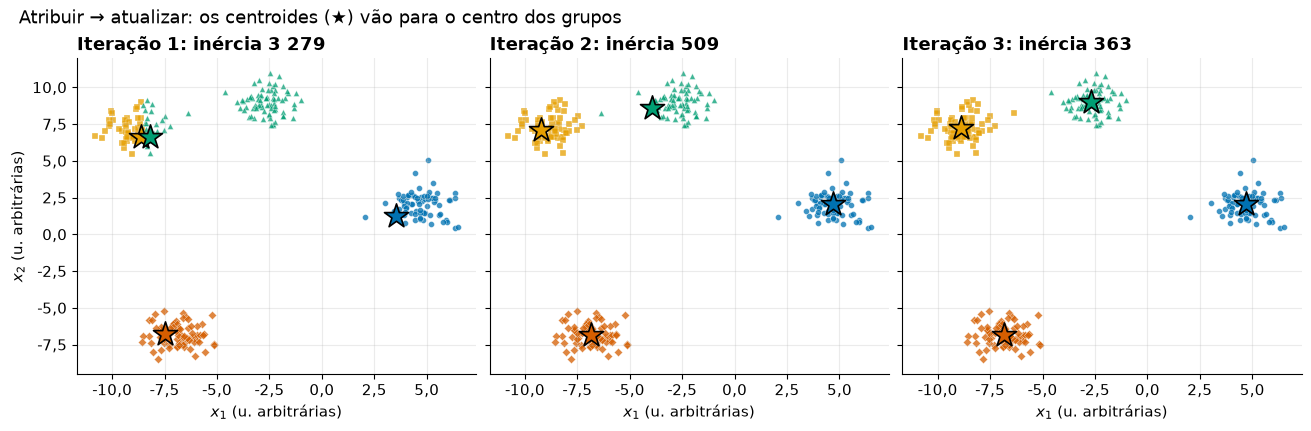

In [15]:
show = [0, 1, 2]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True, sharey=True, layout="constrained")
for ax, i in zip(axes, show):
    cents, labels, inert = history[i]
    for j in range(4):
        m = labels == j
        ax.scatter(X_blobs[m, 0], X_blobs[m, 1], s=18, marker=MARKERS[j], color=CYCLE[j], alpha=0.75,
                   edgecolor="white", linewidth=0.3)
        ax.scatter(*cents[j], marker="*", s=330, color=CYCLE[j], edgecolor="black", linewidth=1.2, zorder=5)
    ax.set(title=f"Iteração {i + 1}: inércia {fmt_pt(inert)}", xlabel="$x_1$ (u. arbitrárias)")
axes[0].set_ylabel("$x_2$ (u. arbitrárias)")
fig.suptitle("Atribuir → atualizar: os centroides (★) vão para o centro dos grupos", x=0.01, ha="left")
finish(fig, FIG / "03_kmeans_steps.png"); plt.show()

Agora o mesmo com `sklearn.cluster.KMeans`. A diferença principal é `n_init`: corre o algoritmo **várias vezes** com inicializações diferentes (e usa `k-means++`, que espalha os centroides iniciais) e fica com a de menor inércia.

In [16]:
km = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(X_blobs)
print(f"sklearn: inércia = {km.inertia_:.1f} | ARI vs grupos reais = {adjusted_rand_score(y_blobs, km.labels_):.3f}")
print(f"à mão  : inércia = {history[-1][2]:.1f} (seed=2, convergiu)")
stuck = run_kmeans(X_blobs, init_centroids(seed=0))
print(f"à mão  : inércia = {stuck[-1][2]:.1f} com seed=0 ({len(stuck)} iterações): mínimo local, dois grupos reais fundidos")

# Mínimos locais: com n_init=1 a inicialização aleatória pode ficar presa numa solução pior
single = [KMeans(4, init="random", n_init=1, random_state=s).fit(X_blobs).inertia_ for s in range(10)]
print("inércia com n_init=1 (10 seeds):", np.round(sorted(single)).astype(int))

sklearn: inércia = 362.5 | ARI vs grupos reais = 1.000
à mão  : inércia = 362.5 (seed=2, convergiu)
à mão  : inércia = 1887.4 com seed=0 (12 iterações): mínimo local, dois grupos reais fundidos
inércia com n_init=1 (10 seeds): [ 362  362  362  362  362 1887 1887 1887 1889 8256]


> ⚠️ **Cuidado:** o K-Means só garante um **mínimo local**. Com uma única inicialização aleatória, algumas seeds podem ficar numa inércia muito pior (acima). Por isso `n_init=10` e `k-means++` são o padrão: o resultado deixa de depender da sorte.

> 🤖 **Ligação à IA:** o mesmo ciclo "atribuir → atualizar" aparece em quantização de vetores, compressão de imagem por cores e na construção de dicionários visuais para modelos de visão.

### 💬 Discussão — Modelação

O K-Means converge sempre. Isso quer dizer que a solução é a *melhor possível*? Que informação extra tens de dar ao algoritmo (e que ele não consegue descobrir sozinho)?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Converge sempre (a inércia nunca aumenta), mas só para um **mínimo local**: com `n_init=1` e inicialização aleatória, as 10 seeds acima dão inércias diferentes (≈ 362 nas melhores, ≈ 1 887 ou mesmo ≈ 8 256 nas piores), e à mão a `seed=0` também ficou presa em ≈ 1 887. E o algoritmo não descobre o **número de grupos** *k*: tem de ser dado por nós, o que leva à secção seguinte.
</details>

<a id="sec-5"></a>

# 5. 🤖 Modeling B — escolher o número de grupos

In [17]:
ks = range(2, 9)
inertias, sils = [], []
for k in ks:
    m = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_blobs)
    inertias.append(m.inertia_)
    sils.append(silhouette_score(X_blobs, m.labels_))
pd.DataFrame({"k": list(ks), "inércia": np.round(inertias, 0), "silhouette": np.round(sils, 3)}).set_index("k").T

k,2,3,4,5,6,7,8
inércia,9211.000,1919.000,362.000,329.000,295.000,262.000,232.000
silhouette,0.603,0.778,0.834,0.698,0.588,0.449,0.332


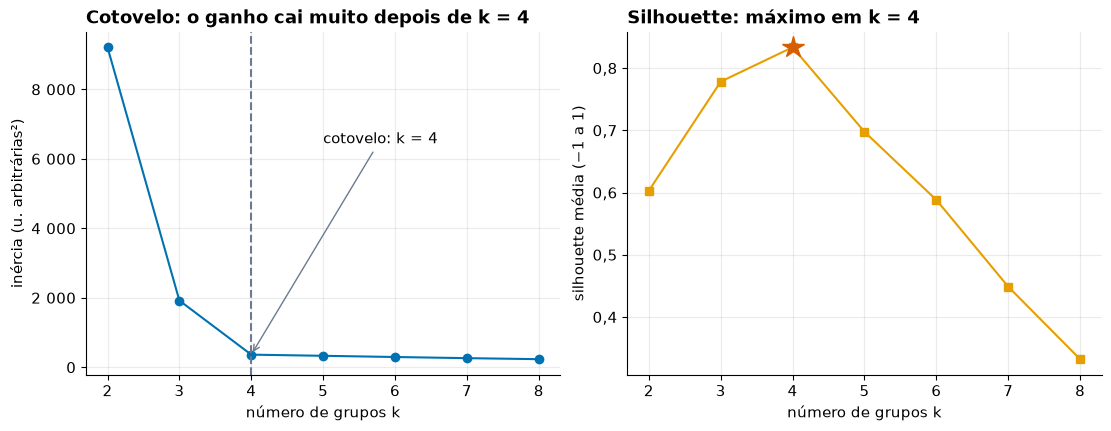

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
axes[0].plot(list(ks), inertias, marker="o", color=PALETTE["blue"])
axes[0].axvline(4, color=PALETTE["grey"], ls="--")
axes[0].annotate("cotovelo: k = 4", (4, inertias[2]), xytext=(5, inertias[0] * 0.7),
                 arrowprops=dict(arrowstyle="->", color=PALETTE["grey"]))
axes[0].set(title="Cotovelo: o ganho cai muito depois de k = 4", xlabel="número de grupos k",
            ylabel="inércia (u. arbitrárias²)")
axes[1].plot(list(ks), sils, marker="s", color=PALETTE["orange"])
axes[1].plot(4, sils[2], marker="*", ms=16, color=PALETTE["red"], zorder=5)
axes[1].set(title="Silhouette: máximo em k = 4", xlabel="número de grupos k", ylabel="silhouette média (−1 a 1)")
finish(fig, FIG / "03_choose_k.png"); plt.show()

- **Cotovelo:** a inércia desce sempre com *k* (no limite, 1 ponto por grupo dá 0). Procuramos o ponto onde o ganho passa a ser pequeno. Aqui: depois de *k* = 4.
- **Silhouette:** para cada ponto compara a distância média ao seu grupo ($a$) com a distância média ao grupo vizinho mais próximo ($b$): $s = (b - a)/\max(a, b)$. Perto de 1: bem arrumado; perto de 0: na fronteira; negativo: provavelmente no grupo errado.

### 💬 Discussão — Dois critérios, uma decisão

Neste conjunto o cotovelo e o silhouette concordam. Num conjunto real do teu trabalho eles discordam (cotovelo sugere 3, silhouette 5). Como decidias?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Aqui ambos apontam para *k* = 4 (a inércia passa de ≈ 1 919 em *k* = 3 para ≈ 362 em *k* = 4, e depois só desce para ≈ 329; o silhouette é máximo, ≈ 0,83, em *k* = 4), o que coincide com os 4 grupos que geramos. Em dados reais é raro ser tão limpo. O cotovelo é visual e subjetivo; o silhouette favorece grupos compactos. Decide-se com o **uso**: quantos segmentos consegue a equipa gerir, se os grupos são **estáveis** com outras seeds ou sub-amostras e se se conseguem **interpretar**.
</details>

<a id="sec-6"></a>

# 6. 🤖 Modeling C — DBSCAN: grupos com forma livre

## 🧠 Como funciona: DBSCAN

**Ideia simples.** Pensa numa festa: um grupo de pessoas forma-se onde há **muita gente junta**; quem está sozinho num canto não pertence a nenhum grupo. O DBSCAN procura "multidões" e deixa os isolados de fora.

Dois parâmetros definem "juntos": o **raio** `eps` (ε, a distância máxima para dois pontos serem vizinhos) e `min_samples` (quantos vizinhos, incluindo o próprio ponto, para haver multidão). Cada ponto fica numa de 3 categorias:

- **núcleo** (*core*): tem pelo menos `min_samples` pontos dentro do raio `eps`. Os núcleos vizinhos ligam-se e crescem o grupo;
- **fronteira** (*border*): está no raio de um núcleo, mas ele próprio não tem vizinhos que cheguem;
- **ruído** (*noise*): não é núcleo nem está perto de um (label −1).

**Quando usar:** grupos de forma livre, ruído a detetar, *k* desconhecido. **Cuidados:** `eps` e `min_samples` têm de ser escolhidos; densidades muito diferentes; escala.

núcleo: 298 | fronteira: 2 | ruído: 3


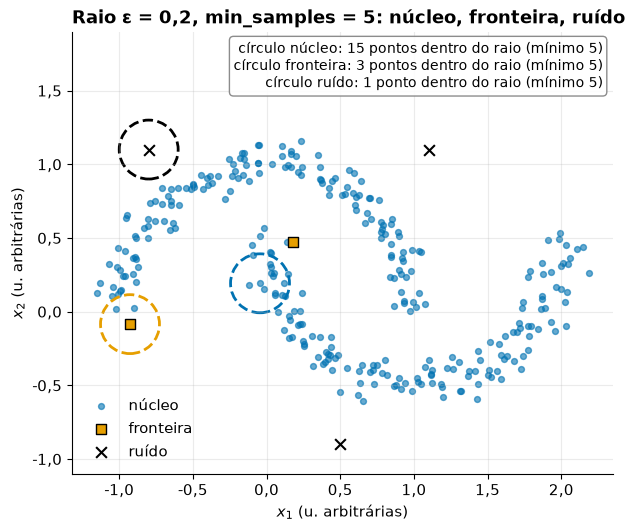

In [19]:
# Mecanismo: luas + 3 pontos isolados que acrescentamos de propósito
demo_X = np.vstack([X_moons, [[-0.8, 1.1], [1.1, 1.1], [0.5, -0.9]]])
EPS, MIN_S = 0.2, 5
demo_db = DBSCAN(eps=EPS, min_samples=MIN_S).fit(demo_X)
is_core = np.zeros(len(demo_X), bool); is_core[demo_db.core_sample_indices_] = True
is_noise = demo_db.labels_ == -1
is_border = ~is_core & ~is_noise
print(f"núcleo: {is_core.sum()} | fronteira: {is_border.sum()} | ruído: {is_noise.sum()}")

# um exemplo de cada tipo
i_core = np.flatnonzero(is_core)[np.argmin(np.linalg.norm(demo_X[is_core] - [0.0, 0.2], axis=1))]
i_border = np.flatnonzero(is_border)[0]
i_noise = np.flatnonzero(is_noise)[0]

fig, ax = plt.subplots(figsize=(8.5, 5.2), layout="constrained")
ax.scatter(*demo_X[is_core].T, s=18, color=PALETTE["blue"], marker="o", label="núcleo", alpha=0.6)
ax.scatter(*demo_X[is_border].T, s=45, color=PALETTE["orange"], marker="s", label="fronteira", edgecolor="black", zorder=3)
ax.scatter(*demo_X[is_noise].T, s=60, color="black", marker="x", label="ruído", zorder=3)
notes = []
for i, name, colour in ((i_core, "núcleo", PALETTE["blue"]), (i_border, "fronteira", PALETTE["orange"]), (i_noise, "ruído", "black")):
    ax.add_patch(plt.Circle(demo_X[i], EPS, fill=False, ec=colour, lw=2, ls="--"))
    n_in = int((np.linalg.norm(demo_X - demo_X[i], axis=1) <= EPS).sum())
    notes.append(f"círculo {name}: {n_in} {'ponto' if n_in == 1 else 'pontos'} dentro do raio (mínimo {MIN_S})")
ax.text(0.98, 0.98, chr(10).join(notes), transform=ax.transAxes, ha="right", va="top", fontsize=10,
        bbox=dict(boxstyle="round", fc="white", ec="grey", alpha=0.9))
ax.set(title=f"Raio ε = {EPS}, min_samples = {MIN_S}: núcleo, fronteira, ruído", xlabel="$x_1$ (u. arbitrárias)", ylabel="$x_2$ (u. arbitrárias)", aspect="equal")
ax.legend(loc="lower left"); ax.set_ylim(-1.1, 1.9)
finish(fig, FIG / "03_dbscan_mechanism.png"); plt.show()

Repara: um ponto é **núcleo** se o círculo tracejado apanhar pelo menos `min_samples` pontos (ele próprio incluído). O de **fronteira** está dentro do círculo de um núcleo mas o seu próprio círculo está quase vazio. O de **ruído** tem o círculo vazio e ninguém o "adota".

O **DBSCAN** (*Density-Based Spatial Clustering of Applications with Noise*) define grupo como uma região **densa**: um ponto é *núcleo* se tiver pelo menos `min_samples` vizinhos a uma distância `eps`; grupos são cadeias de núcleos ligados; o que sobra é **ruído** (label −1). Não precisa de *k*, mas precisa de `eps`.

Primeiro, o K-Means (que procura bolas) nas luas:

In [20]:
km_moons = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit(X_moons)
db_moons = DBSCAN(eps=0.2, min_samples=5).fit(X_moons)

def summarize(name, labels, X, y):
    n_clusters = len(set(labels) - {-1})
    sil = silhouette_score(X, labels) if n_clusters > 1 else float("nan")
    print(f"{name:<18} clusters={n_clusters}  ruído={int((labels == -1).sum()):>3}  "
          f"silhouette={sil:.3f}  ARI vs verdade={adjusted_rand_score(y, labels):.3f}")

summarize("K-Means (k=2)", km_moons.labels_, X_moons, y_moons)
summarize("DBSCAN (eps=0.2)", db_moons.labels_, X_moons, y_moons)

K-Means (k=2)      clusters=2  ruído=  0  silhouette=0.485  ARI vs verdade=0.254
DBSCAN (eps=0.2)   clusters=2  ruído=  0  silhouette=0.329  ARI vs verdade=1.000


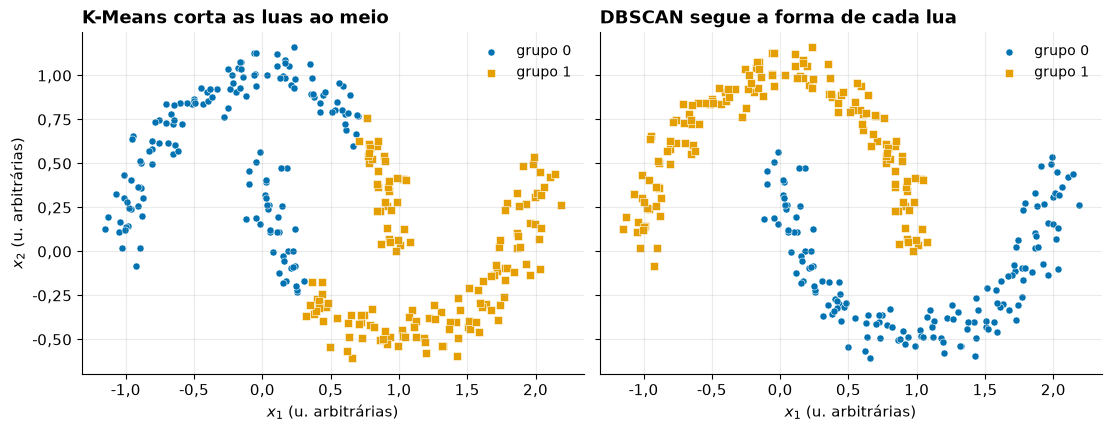

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True, layout="constrained")
for ax, labels, title in ((axes[0], km_moons.labels_, "K-Means corta as luas ao meio"),
                          (axes[1], db_moons.labels_, "DBSCAN segue a forma de cada lua")):
    for k in sorted(set(labels)):
        m = labels == k
        if k == -1:
            ax.scatter(X_moons[m, 0], X_moons[m, 1], marker="x", s=50, color="black", label="ruído")
        else:
            ax.scatter(X_moons[m, 0], X_moons[m, 1], s=26, marker=MARKERS[k], color=CYCLE[k], edgecolor="white",
                       linewidth=0.4, label=f"grupo {k}")
    ax.set(title=title, xlabel="$x_1$ (u. arbitrárias)"); ax.legend(fontsize=10)
axes[0].set_ylabel("$x_2$ (u. arbitrárias)")
finish(fig, FIG / "03_moons_kmeans_vs_dbscan.png"); plt.show()

### O parâmetro `eps`: pequeno demais fragmenta, grande demais junta

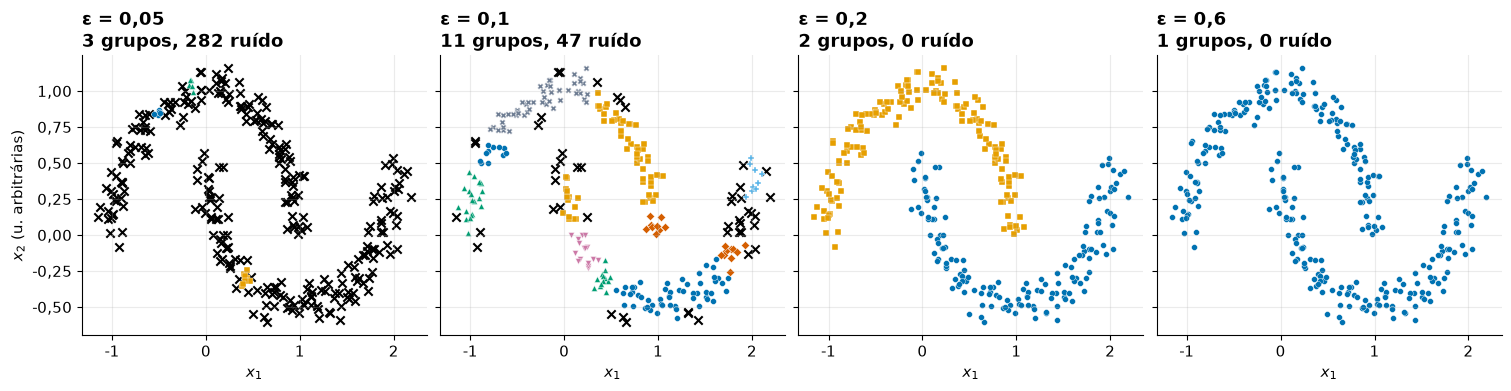

In [22]:
eps_values = [0.05, 0.1, 0.2, 0.6]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharex=True, sharey=True, layout="constrained")
for ax, eps in zip(axes, eps_values):
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_moons)
    for k in sorted(set(labels)):
        m = labels == k
        if k == -1:
            ax.scatter(X_moons[m, 0], X_moons[m, 1], marker="x", s=36, color="black")
        else:
            ax.scatter(X_moons[m, 0], X_moons[m, 1], s=18, marker=MARKERS[k % 7], color=CYCLE[k % 7],
                       edgecolor="white", linewidth=0.3)
    ax.set(title=f"ε = {eps}\n{len(set(labels) - {-1})} grupos, {(labels == -1).sum()} ruído", xlabel="$x_1$")
axes[0].set_ylabel("$x_2$ (u. arbitrárias)")
finish(fig, FIG / "03_dbscan_eps.png"); plt.show()

> 💡 **Dica:** para escolher `eps` no mundo real, desenha-se a distância de cada ponto ao seu *k*-ésimo vizinho (gráfico *k-distance*, `NearestNeighbors`) e procura-se o "cotovelo" da curva.

> ⚠️ **Cuidado:** o DBSCAN também usa distâncias, por isso a **escala** continua a importar. E tem dificuldade com grupos de densidades muito diferentes (um `eps` único não serve para todos).

### 💬 Discussão — Quando é que o DBSCAN é a escolha certa?

Vê os 4 painéis de `eps`. Que erro acontece com `eps` pequeno? E com `eps` grande? E o que fazer com os pontos marcados como ruído numa aplicação real (por exemplo, transações bancárias)?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Com `eps` pequeno (0,05 e 0,1) as luas estilhaçam-se em vários micro-grupos e há muito ruído (com 0,1 são 11 grupos e 47 pontos de ruído); com `eps` = 0,2 aparecem as 2 luas sem ruído; com `eps` grande as luas fundem-se num único grupo (vê o último painel). O ruído não é "lixo": numa aplicação de fraude ou manutenção, os pontos que não pertencem a nenhum grupo denso são precisamente os candidatos a **anomalias** para revisão humana.
</details>

<a id="sec-7"></a>

# 7. 🤖 Modeling D — PCA: comprimir sem perder o essencial

## 🧠 Como funciona: PCA

**Ideia simples.** Uma nuvem de pontos 3D pode ter forma de "panqueca": quase tudo acontece em 2 direções. A PCA (*Principal Component Analysis*, análise de componentes principais) encontra **as direções em que os dados mais variam** (a **variância** é o quanto os valores se espalham). A 1.ª componente é a direção de maior espalhamento; a 2.ª, perpendicular, a seguinte; e assim por diante. Guardar só as primeiras componentes é **comprimir** com pouca perda.

**Passos:** (1) centrar os dados na média; (2) achar a direção de maior variância; (3) achar a seguinte, perpendicular às anteriores; (4) projetar cada ponto nessas direções (as novas "coordenadas"). Não precisa de *labels*.

**Quando usar:** reduzir dimensões, visualizar, limpar ruído. **Cuidados:** é linear; mede variância, não "importância para a tarefa"; depende da escala das colunas.

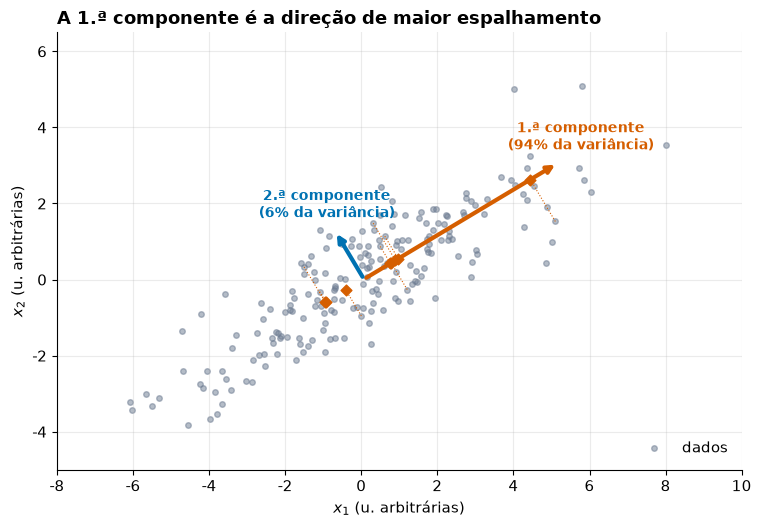

In [23]:
# Mecanismo: nuvem 2D alongada e as suas duas componentes principais
rng = np.random.default_rng(SEED)
cloud = rng.normal(size=(200, 2)) * [3.0, 0.8]                  # espalhada ao longo do eixo x
theta = np.deg2rad(30)
cloud = cloud @ np.array([[np.cos(theta), np.sin(theta)], [-np.sin(theta), np.cos(theta)]])
pca2 = PCA(n_components=2).fit(cloud)
centre = pca2.mean_
fig, ax = plt.subplots(figsize=(7.5, 5.2), layout="constrained")
ax.scatter(cloud[:, 0], cloud[:, 1], s=16, color=PALETTE["grey"], alpha=0.5, label="dados")
for k, (colour, name) in enumerate(((PALETTE["red"], "1.ª componente"), (PALETTE["blue"], "2.ª componente"))):
    vec = pca2.components_[k] * 2 * np.sqrt(pca2.explained_variance_[k])
    ax.annotate("", xy=centre + vec, xytext=centre, arrowprops=dict(arrowstyle="-|>", color=colour, lw=3))
    ax.text(*(centre + vec * (1.12 if k == 0 else 1.3)), f"{name}" + chr(10) + f"({pca2.explained_variance_ratio_[k]:.0%} da variância)", color=colour, fontsize=10, fontweight="bold", ha="center")
# projeção de alguns pontos na 1.ª componente
for i in range(0, 200, 25):
    proj = centre + (cloud[i] - centre) @ pca2.components_[0] * pca2.components_[0]
    ax.plot([cloud[i, 0], proj[0]], [cloud[i, 1], proj[1]], color=PALETTE["red"], lw=0.8, ls=":")
    ax.scatter(*proj, s=30, color=PALETTE["red"], marker="D", zorder=4)
ax.set(title="A 1.ª componente é a direção de maior espalhamento", xlabel="$x_1$ (u. arbitrárias)", ylabel="$x_2$ (u. arbitrárias)", aspect="equal")
ax.legend(loc="lower right"); ax.set_xlim(-8, 10); ax.set_ylim(-5, 6.5); finish(fig, FIG / "03_pca_mechanism.png"); plt.show()

Os losangos vermelhos são a **projeção** dos pontos na 1.ª componente: ficamos com **1 número por ponto em vez de 2** e perdemos só a pequena distância perpendicular (a variância da 2.ª componente). É isto que vamos fazer com os dígitos: de 64 números para 2, 10 ou 29.

Agora nos dígitos (as imagens já foram vistas na secção 2):

2 componentes explicam 28.5% | 10 explicam 73.8% | 30 explicam 95.9%
Para 95 % da variância bastam 29 componentes (de 64)


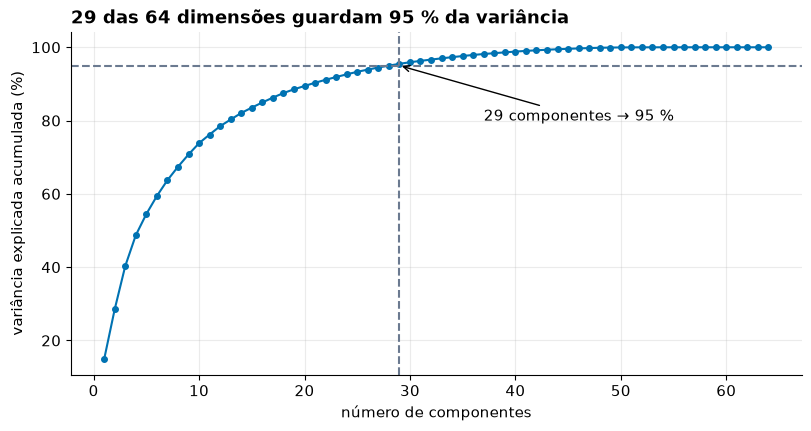

In [24]:
pca = PCA(random_state=SEED).fit(digits.data)
cum = np.cumsum(pca.explained_variance_ratio_)
k95 = int(np.searchsorted(cum, 0.95) + 1)
print(f"2 componentes explicam {cum[1]:.1%} | 10 explicam {cum[9]:.1%} | 30 explicam {cum[29]:.1%}")
print(f"Para 95 % da variância bastam {k95} componentes (de 64)")

fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
ax.plot(range(1, 65), cum * 100, marker="o", ms=4, color=PALETTE["blue"])
ax.axhline(95, color=PALETTE["grey"], ls="--"); ax.axvline(k95, color=PALETTE["grey"], ls="--")
ax.annotate(f"{k95} componentes → 95 %", (k95, 95), xytext=(k95 + 8, 80), arrowprops=dict(arrowstyle="->"))
ax.set(title=f"{k95} das 64 dimensões guardam 95 % da variância", xlabel="número de componentes",
       ylabel="variância explicada acumulada (%)")
finish(fig, FIG / "03_pca_variance.png"); plt.show()

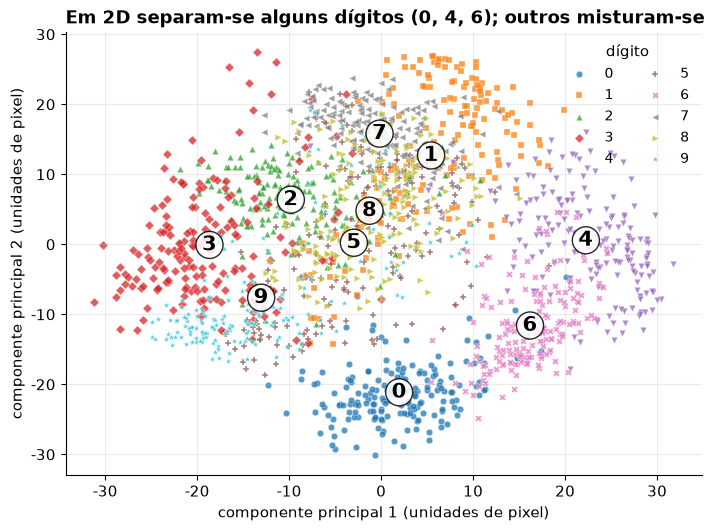

In [25]:
Z = PCA(n_components=2, random_state=SEED).fit_transform(digits.data)
palette10 = plt.cm.tab10(np.arange(10))
markers10 = ["o", "s", "^", "D", "v", "P", "X", "<", ">", "*"]

fig, ax = plt.subplots(figsize=(7, 5.2), layout="constrained")
for d in range(10):
    m = digits.target == d
    ax.scatter(Z[m, 0], Z[m, 1], s=22, marker=markers10[d], color=palette10[d], alpha=0.75, edgecolor="white",
               linewidth=0.3, label=str(d))
    ax.text(*Z[m].mean(axis=0), str(d), fontsize=15, fontweight="bold", ha="center", va="center",
            bbox=dict(boxstyle="circle,pad=0.15", fc="white", ec="black", alpha=0.85))
ax.set(title="Em 2D separam-se alguns dígitos (0, 4, 6); outros misturam-se",
       xlabel="componente principal 1 (unidades de pixel)", ylabel="componente principal 2 (unidades de pixel)")
ax.legend(title="dígito", ncol=2, fontsize=10, loc="upper right")
finish(fig); fig.savefig(FIG / "03_pca_digits_2d.png", dpi=100); plt.show()

### Reconstrução: quanto se perde ao comprimir?

`inverse_transform` volta a projetar as componentes mantidas para o espaço de 64 pixéis. Quanto menos componentes, mais desfocada a imagem.

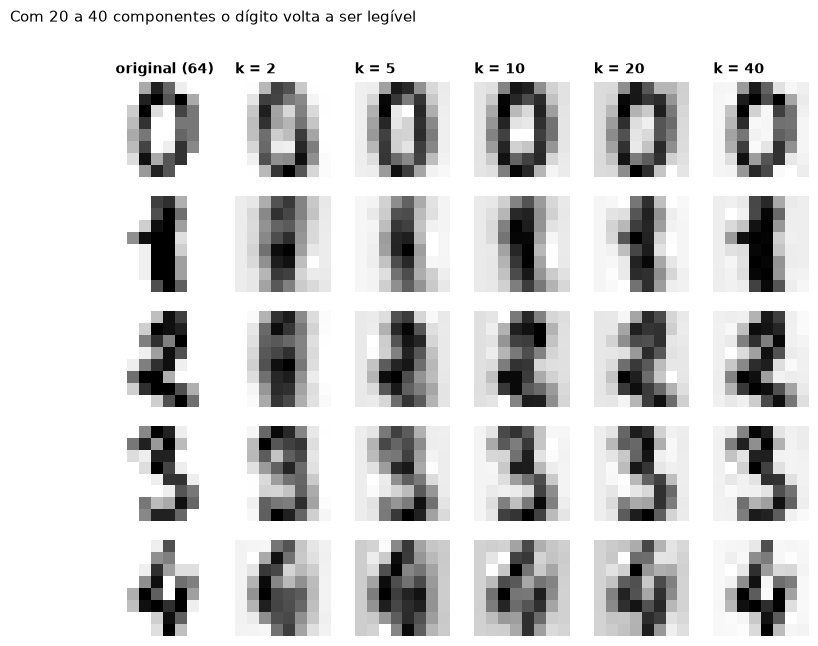

In [26]:
ks_rec = [2, 5, 10, 20, 40]
sample_idx = [0, 1, 2, 3, 4]
fig, axes = plt.subplots(len(sample_idx), len(ks_rec) + 1, figsize=(9, 7.2))
for r, idx in enumerate(sample_idx):
    axes[r, 0].imshow(digits.images[idx], cmap="gray_r"); axes[r, 0].axis("off")
    if r == 0: axes[r, 0].set_title("original (64)", fontsize=10)
    for c, k in enumerate(ks_rec, 1):
        p = PCA(n_components=k, random_state=SEED).fit(digits.data)
        rec = p.inverse_transform(p.transform(digits.data[[idx]]))
        axes[r, c].imshow(rec.reshape(8, 8), cmap="gray_r"); axes[r, c].axis("off")
        if r == 0: axes[r, c].set_title(f"k = {k}", fontsize=10)
fig.suptitle("Com 20 a 40 componentes o dígito volta a ser legível", x=0.01, ha="left", fontsize=11)
finish(fig, FIG / "03_pca_reconstruction.png"); plt.show()

### 💬 Discussão — Compressão e visualização

Guardar 29 números em vez de 64 por imagem (95 % da variância) parece um bom negócio. Em que situações **não** é? E o gráfico 2D: podes confiar que dígitos próximos são realmente parecidos?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

A PCA é **linear** e guarda a variância, não necessariamente o que interessa para uma tarefa (um detalhe pequeno que distingue um 3 de um 8 pode ter pouca variância e ser descartado). No gráfico 2D só ≈ 29 % da variância (2 componentes) está representada, por isso a mistura de dígitos como 5, 8 e 9 pode ser só efeito de projeção: em 64 dimensões podem estar separados. Para uma visualização não linear existem o t-SNE e o UMAP, mais caros e mais difíceis de interpretar.
</details>

<a id="sec-8"></a>

# 8. 📏 Evaluation (avaliação): como avaliar sem labels?

Duas famílias de métricas:

- **Internas** (só usam os dados): *silhouette*, inércia. Medem compacidade e separação.
- **Externas** (precisam de labels escondidas): ARI, que só podemos calcular porque os conjuntos de brinquedo têm verdade conhecida. **No mundo real normalmente não existe.**

O ponto delicado: uma métrica interna mede *uma noção* de bom agrupamento (bolas compactas), que pode não ser a do problema.

In [27]:
rows = []
for name, labels, X, y in (("luas · K-Means k=2", km_moons.labels_, X_moons, y_moons),
                           ("luas · DBSCAN eps=0.2", db_moons.labels_, X_moons, y_moons)):
    rows.append({"modelo": name, "silhouette (interna)": round(silhouette_score(X, labels), 3),
                 "ARI (externa)": round(adjusted_rand_score(y, labels), 3)})
pd.DataFrame(rows).set_index("modelo")

,silhouette (interna),ARI (externa)
modelo,,
luas · K-Means k=2,0.485,0.254
luas · DBSCAN eps=0.2,0.329,1.000


**O silhouette dá melhor nota ao K-Means errado** (≈ 0,48 contra ≈ 0,33 do DBSCAN), enquanto o ARI mostra a verdade: o K-Means acerta pouco (ARI ≈ 0,25) e o DBSCAN acerta tudo (ARI = 1,0). O silhouette premeia grupos compactos e redondos; duas luas bem separadas mas encurvadas pontuam mal.

In [28]:
# Digits: o K-Means nos pixéis vs nas componentes principais (ARI contra os dígitos reais)
rows = []
for k in (2, 5, 10, 20, 64):
    Zk = PCA(n_components=k, random_state=SEED).fit_transform(digits.data) if k < 64 else digits.data
    labels = KMeans(n_clusters=10, n_init=10, random_state=SEED).fit_predict(Zk)
    rows.append({"dimensões usadas": k, "ARI vs dígito real": round(adjusted_rand_score(digits.target, labels), 3)})
pd.DataFrame(rows).set_index("dimensões usadas").T

dimensões usadas,2,5,10,20,64
ARI vs dígito real,0.388,0.556,0.654,0.67,0.667


Sem usar nunca a label, o K-Means encontra um agrupamento com ARI ≈ 0,67 nos 64 pixéis; só com 2 componentes cai para ≈ 0,39 (informação perdida), com 5 sobe para ≈ 0,56 e a partir de 10 componentes (≈ 0,65) fica quase ao nível dos 64 pixéis, com menos custo.

### 💬 Discussão — Avaliação

O silhouette escolheu o K-Means nas luas, o ARI escolheu o DBSCAN. Num problema real não tens o ARI. Como evitas ser enganado por uma métrica interna?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Nunca confiar numa só métrica: combinar (1) **visualização** (PCA/2D), (2) **estabilidade** (repetir com outras seeds ou sub-amostras, e ver se os grupos persistem), (3) **validação externa indireta** (os grupos separam uma variável que **não** usámos? nas casas, o preço), e (4) **utilidade** para a decisão. As luas mostram porquê: o silhouette = 0,48 do K-Means errado é maior que o 0,33 do DBSCAN certo.
</details>

<a id="sec-9"></a>

# 9. 🚀 Deployment (implementação) e limites

Pôr *clustering* em produção levanta perguntas que a supervisionada não levanta:

- **Atribuir casos novos:** `KMeans.predict` funciona; o DBSCAN **não tem** `predict` (só `fit_predict`): terias de refazer ou usar um classificador por cima.
- **Estabilidade:** com dados novos os grupos mudam; os rótulos 0, 1, 2 também (o "cluster 0" de hoje pode ser o "cluster 2" de amanhã).
- **Deriva** (*drift*): se a população muda (casas de outro bairro), os grupos deixam de fazer sentido.
- **Ética:** segmentar pessoas pode discriminar sem ninguém ter decidido isso; revê que *features* entram.

### 💬 Discussão — Do protótipo à produção

A imobiliária quer usar os 3 segmentos de casas para etiquetar anúncios novos todos os meses. Que riscos vês, e que verificações automáticas porias?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Riscos: (a) os rótulos mudam entre execuções, pelo que se deve **fixar o modelo** (guardar o *pipeline* com `StandardScaler` + `KMeans` e aplicar `predict`, em vez de reajustar); (b) *drift*: monitorizar a distância média ao centroide e a proporção de casas por segmento; (c) 1987 não é hoje, ou seja, os segmentos aprendidos com Windsor-1987 não se transferem; (d) o nome "segmento barato" pode estigmatizar um bairro. Verificações: alertas quando a distribuição dos segmentos ou a inércia por ponto sair de um intervalo.
</details>

<a id="sec-10"></a>

# 10. ✏️ Exercícios

### ✏️ Exercício 1 — O melhor k para as casas

**Dificuldade:** ⭐

Com as 5 colunas **escaladas** das casas, calcula o silhouette para *k* de 2 a 6 e diz qual *k* escolhias.

In [29]:
Xs = StandardScaler().fit_transform(X_house)
# TODO: para k em 2..6, ajusta KMeans(k, n_init=10, random_state=SEED) e imprime o silhouette

<details>
<summary>💡 Ver solução</summary>

O silhouette é em geral mais alto para *k* pequeno em dados reais sem separação clara, e o valor é baixo (< 0,4): os segmentos são contínuos, não ilhas. Escolher entre *k* = 2 e 3 deve ser feito pela utilidade e pela interpretação dos perfis.

```python
for k in range(2, 7):
    lab = KMeans(k, n_init=10, random_state=SEED).fit_predict(Xs)
    print(k, round(silhouette_score(Xs, lab), 3))
```
</details>

### ✏️ Exercício 2 — min_samples no DBSCAN

**Dificuldade:** ⭐⭐

Nas luas, fixa `eps=0.2` e varia `min_samples` em 3, 5, 10, 20, 40. Quantos clusters e quantos pontos de ruído aparecem em cada caso? O que acontece quando `min_samples` é muito grande?

In [30]:
# TODO

<details>
<summary>💡 Ver solução</summary>

`min_samples` grande exige vizinhanças mais densas: mais pontos passam a ruído e, a partir de certo valor, os clusters desfazem-se ou desaparecem. Pequeno: aceita tudo e tende a juntar grupos. `eps` e `min_samples` têm de ser afinados em conjunto.

```python
for ms in (3, 5, 10, 20, 40):
    lab = DBSCAN(eps=0.2, min_samples=ms).fit_predict(X_moons)
    print(ms, len(set(lab) - {-1}), 'clusters', (lab == -1).sum(), 'ruído')
```
</details>

### ✏️ Exercício 3 — Erro de reconstrução vs componentes

**Dificuldade:** ⭐⭐⭐

Para k = 1, 2, 5, 10, 20, 30, 40, 63, calcula o erro quadrático médio de reconstrução de `digits.data` e desenha-o (eixo y em escala log). Em que k a curva "achata"? Relaciona com a variância explicada acumulada.

In [31]:
# TODO: PCA(k).fit(...), inverse_transform(transform(...)), média de (original - reconstruído)**2

<details>
<summary>💡 Ver solução</summary>

O erro diminui monotonamente e é a variância que fica por explicar (a soma das variâncias das componentes descartadas, por pixel). A curva desce depressa até ≈ 30 componentes, quando a variância acumulada já passa os 95 %, e depois ganha-se pouco.

```python
ks = [1, 2, 5, 10, 20, 30, 40, 63]
errs = []
for k in ks:
    p = PCA(k, random_state=SEED).fit(digits.data)
    rec = p.inverse_transform(p.transform(digits.data))
    errs.append(((digits.data - rec) ** 2).mean())
fig, ax = plt.subplots()
ax.semilogy(ks, errs, marker='o')
ax.set(xlabel='componentes', ylabel='erro quadrático médio (pixel²)', title='O erro de reconstrução desce com k')
plt.show()
```
</details>

<a id="sec-11"></a>

# 11. 📌 Resumo

| Ideia | Em uma linha |
|---|---|
| **K-Means** | atribuir ao centroide mais próximo ↔ atualizar centroides para a média; converge para um mínimo local (`n_init`, `k-means++`) |
| **Escala** | distâncias dependem das unidades; sem `StandardScaler`, o `lotsize` decidiu sozinho (ARI = 1,0) |
| **Escolher k** | cotovelo (inércia) + silhouette + estabilidade + utilidade; nenhum é infalível |
| **DBSCAN** | grupos = regiões densas; `eps` e `min_samples`; devolve ruído (−1); sem `predict` |
| **PCA** | eixos de máxima variância; 29 componentes guardam 95 % dos dígitos; boa para ver e comprimir |
| **Avaliar sem labels** | silhouette favorece bolas (0,48 K-Means errado > 0,33 DBSCAN certo nas luas); combinar métricas, visualização e utilidade |
| **CRISP-DM** | os grupos só valem se forem interpretáveis, estáveis e acionáveis |

**Checklist:** ☐ escalei? ☐ tentei vários *k* e seeds? ☐ a forma dos grupos é redonda? ☐ interpretei com variáveis que não usei? ☐ sei como atribuir casos novos?

<a id="sec-12"></a>

# 12. 📚 Para saber mais

- scikit-learn User Guide, *Clustering*: <https://scikit-learn.org/stable/modules/clustering.html> (K-Means, DBSCAN, métricas de avaliação).
- scikit-learn User Guide, *PCA*: <https://scikit-learn.org/stable/modules/decomposition.html#pca>.
- Chapman et al. (2000). *CRISP-DM 1.0: Step-by-step data mining guide*. SPSS/NCR/DaimlerChrysler.
- Dados das casas: Anglin & Gençay (1996), *Journal of Applied Econometrics* 11(6):633–648 (pacote R AER).
- Extensões (só menção): Gaussian Mixtures (clusters probabilísticos), clustering hierárquico, t-SNE/UMAP, autoencoders (PCA não linear).

---
<div align="center">

⬅️ [Anterior: 02 · CRISP-DM: Titanic](../../01_supervised_learning/notebooks/02_CRISP-DM_Titanic_Survival.ipynb) &nbsp;·&nbsp; 🏠 [Lição 02](../../README.md) &nbsp;·&nbsp; [Seguinte: 04 · Redes neuronais do zero](../../03_neural_networks/notebooks/04_Neural_Networks_From_Scratch.ipynb) ➡️

**The AI Learning Hub** · Lição 02 — Machine Learning: fundamentos<br>
Diogo Freitas & João Francisco Botas · Licença MIT

</div>